# Weighted Matrix Factorization / Implicit ALS — Double Descent in One-Class Collaborative Filtering

Model: Weighted MF / implicit ALS (Hu, Koren, Volinsky, 2008), fit with the `implicit` Python library.
This is **not** a variant of NMF: there is no non-negativity constraint on the factors, and training
uses every cell of the user-item matrix (weighted by confidence) instead of a sampled negative support.

This notebook runs the same experiment at five user-activity thresholds (`MIN_INTERACTIONS` = 3, 5, 10,
20, 25) and summarizes what changes across them. Every result below is either computed live in this
notebook or loaded from a results file that this same notebook produced in an earlier run (the sweep
over k is expensive, so it is cached to disk and only recomputed if the cache is missing).

## 0. Environment and configuration

In [2]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"  # avoids oversubscription when implicit also multi-threads

import time
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.sparse import load_npz, csr_matrix
import matplotlib.pyplot as plt

try:
    import google.colab  # noqa: F401
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = Path('/content/drive/MyDrive/Progetto_Recommendation_System')
except ImportError:
    # Running locally: assumes the notebook lives inside the project folder.
    BASE_DIR = Path.cwd()

DATA_REAL_DIR = BASE_DIR / "data" / "real"

SEED = 20060709
K_GRID = [1, 2, 4, 8, 16, 24, 32, 48, 64, 96, 128, 192, 256, 384, 512, 768, 1024, 1536, 2048, 3072]

ALPHA = 40.0
REG_LAMBDA = 0.01
METRIC_K_LIST = [5, 10, 20]
R_EVAL = 1

# Every result in this notebook is computed on CPU.
USE_GPU = False

print("BASE_DIR:", BASE_DIR, "- exists:", BASE_DIR.exists())

BASE_DIR: /sessions/determined-zealous-bohr/mnt/Progetto_Recommendation_System - exists: True


## 1. Loading the real interaction data

This is shared across all five thresholds — the threshold only affects the train/test split, not the
raw interaction log.

In [4]:
utility_matrix_real = load_npz(DATA_REAL_DIR / "utility_matrix_real_binary.npz")
user_index = pd.read_csv(DATA_REAL_DIR / "user_index.csv")
work_index = pd.read_csv(DATA_REAL_DIR / "work_index.csv")
interactions_real_long = pd.read_csv(DATA_REAL_DIR / "interactions_real_long.csv")

assert utility_matrix_real.shape == (len(user_index), len(work_index))
assert (interactions_real_long["interaction_source"] == "observed").all()
print("Full interaction matrix:", utility_matrix_real.shape, "- non-zero entries:", utility_matrix_real.nnz)

Full interaction matrix: (23605, 4405) - non-zero entries: 136832


## 2. Train/test split, training matrix, and evaluation set (reusable for any threshold)

The same three steps (leave-one-out split, sparse training matrix, pointwise evaluation set) are needed
once per threshold. Instead of repeating the same cells five times, they are wrapped in one function,
`prepare_threshold_data`, called once per threshold below.

In [6]:
KEEP_COLS = ["customer_id_anon", "work_id", "distinct_orders", "units",
             "total_spend", "first_purchase", "last_purchase", "binary_utility"]

def build_train_test(df, min_interactions, seed):
    '''Random leave-one-out split per user. Same logic agreed with the NMF team (Gianluca/Denis):
    one held-out interaction per user, cold-start test items (never seen in train) are dropped.'''
    per_user = df.groupby("customer_id_anon")["work_id"].transform("size")
    kept = df[per_user >= min_interactions].copy()
    kept = kept.sample(frac=1, random_state=seed).reset_index(drop=True)
    pick = kept.groupby("customer_id_anon").cumcount()
    test = kept[pick == 0].copy()
    train = kept[pick != 0].copy()
    train_items = set(train["work_id"].unique())
    cold = ~test["work_id"].isin(train_items)
    n_cold = int(cold.sum())
    test = test[~cold].copy()
    assert train.duplicated(["customer_id_anon", "work_id"]).sum() == 0
    assert test.duplicated(["customer_id_anon", "work_id"]).sum() == 0
    leak = test.merge(train[["customer_id_anon", "work_id"]], on=["customer_id_anon", "work_id"], how="inner")
    assert len(leak) == 0, "train/test leakage!"
    assert train.groupby("customer_id_anon").size().min() >= min_interactions - 1
    return train[KEEP_COLS].copy(), test[KEEP_COLS].copy(), n_cold


def prepare_threshold_data(min_interactions, splits_dir):
    '''Build the split, the sparse training matrix, and the pointwise evaluation set for one
    user-activity threshold. Returns a dict; the caller assigns these into the globals that
    evaluate_k() reads (train_csr, test_user_idx, test_item_idx, neg_items_per_user, n_items_train).'''
    splits_dir.mkdir(parents=True, exist_ok=True)

    train_df, test_df, n_cold = build_train_test(interactions_real_long, min_interactions, SEED)
    train_df.to_csv(splits_dir / "train.csv", index=False)
    test_df.to_csv(splits_dir / "test.csv", index=False)

    train_users = np.sort(train_df["customer_id_anon"].unique())
    train_items = np.sort(train_df["work_id"].unique())
    train_user_index = pd.DataFrame({"customer_id_anon": train_users, "train_user_idx": np.arange(len(train_users))})
    train_work_index = pd.DataFrame({"work_id": train_items, "train_item_idx": np.arange(len(train_items))})
    train_user_index.to_csv(splits_dir / "train_user_index.csv", index=False)
    train_work_index.to_csv(splits_dir / "train_work_index.csv", index=False)

    train_merged = train_df.merge(train_user_index, on="customer_id_anon").merge(train_work_index, on="work_id")
    n_users_train = len(train_user_index)
    n_items_train = len(train_work_index)

    train_csr = csr_matrix(
        (train_merged["binary_utility"].astype(np.float32),
         (train_merged["train_user_idx"], train_merged["train_item_idx"])),
        shape=(n_users_train, n_items_train),
    )
    assert train_csr.nnz == len(train_df)

    test_m = test_df.merge(train_user_index, on="customer_id_anon").merge(train_work_index, on="work_id")
    assert len(test_m) == len(test_df)
    test_user_idx = test_m["train_user_idx"].to_numpy()
    test_item_idx = test_m["train_item_idx"].to_numpy()

    rng = np.random.default_rng(SEED)
    neg_items_per_user = []
    for u in test_user_idx:
        liked = set(train_csr[u].indices.tolist())
        liked.add(-1)
        negs = []
        while len(negs) < R_EVAL:
            cand = int(rng.integers(0, n_items_train))
            if cand not in liked:
                negs.append(cand)
                liked.add(cand)
        neg_items_per_user.append(negs)

    print(f"min_interactions={min_interactions}: train users={n_users_train}, train items={n_items_train}, "
          f"test users={len(np.unique(test_user_idx))}, cold-start test rows dropped={n_cold}")

    return dict(train_csr=train_csr, test_user_idx=test_user_idx, test_item_idx=test_item_idx,
                neg_items_per_user=neg_items_per_user, n_users_train=n_users_train, n_items_train=n_items_train)

## 3. Model: Weighted MF / iALS (`implicit` library)

`evaluate_k` fits one model at a given number of latent factors `k`, then computes both the ranking
metrics (Recall@K, NDCG@K, MAP@K — full-catalogue scoring, training positives masked out) and a
pointwise RMSE (on the held-out positive plus `R_EVAL` sampled negatives per user).

In [8]:
from implicit.als import AlternatingLeastSquares

def evaluate_k(k, iterations, factors_alpha=ALPHA, reg=REG_LAMBDA, seed=SEED):
    if factors_alpha is None or reg is None:
        raise ValueError("ALPHA / REG_LAMBDA not set: refusing to silently fall back to made-up values.")
    if iterations is None:
        raise ValueError("iterations not set explicitly (see the convergence check below for why this matters).")

    t0 = time.time()
    model = AlternatingLeastSquares(factors=k, regularization=reg, alpha=factors_alpha,
                                     iterations=iterations, random_state=seed, use_gpu=False)
    model.fit(train_csr, show_progress=False)
    fit_time = time.time() - t0

    user_factors = model.user_factors
    item_factors = model.item_factors

    t1 = time.time()
    unique_users = np.unique(test_user_idx)
    N = max(METRIC_K_LIST)
    user_rows = train_csr[unique_users]
    ids, _scores = model.recommend(unique_users, user_rows, N=N, filter_already_liked_items=True)
    user_to_row = {u: i for i, u in enumerate(unique_users)}

    metrics = {f"ndcg@{K}": [] for K in METRIC_K_LIST}
    metrics.update({f"recall@{K}": [] for K in METRIC_K_LIST})
    metrics.update({f"map@{K}": [] for K in METRIC_K_LIST})

    for u, relevant in zip(test_user_idx, test_item_idx):
        ranked = ids[user_to_row[u]]
        for K in METRIC_K_LIST:
            topk = ranked[:K]
            hit = relevant in topk
            metrics[f"recall@{K}"].append(1.0 if hit else 0.0)
            if hit:
                rank = int(np.where(topk == relevant)[0][0]) + 1
                metrics[f"ndcg@{K}"].append(1.0 / np.log2(rank + 1))
                metrics[f"map@{K}"].append(1.0 / rank)
            else:
                metrics[f"ndcg@{K}"].append(0.0)
                metrics[f"map@{K}"].append(0.0)
    ranking_time = time.time() - t1

    t2 = time.time()
    y_true, y_score = [], []
    for idx_local, (u, pos_item) in enumerate(zip(test_user_idx, test_item_idx)):
        y_true.append(1.0); y_score.append(float(user_factors[u] @ item_factors[pos_item]))
        for neg_item in neg_items_per_user[idx_local]:
            y_true.append(0.0); y_score.append(float(user_factors[u] @ item_factors[neg_item]))
    y_true = np.array(y_true); y_score = np.array(y_score)
    brier = float(np.mean((y_true - y_score) ** 2))
    rmse = float(np.sqrt(brier))
    pointwise_time = time.time() - t2

    row = {"k": k, "iterations": iterations, "use_gpu": False,
           "fit_time_s": fit_time, "ranking_time_s": ranking_time, "pointwise_time_s": pointwise_time,
           "rmse": rmse, "brier": brier}
    for K in METRIC_K_LIST:
        row[f"ndcg@{K}"] = float(np.mean(metrics[f"ndcg@{K}"]))
        row[f"recall@{K}"] = float(np.mean(metrics[f"recall@{K}"]))
        row[f"map@{K}"] = float(np.mean(metrics[f"map@{K}"]))
    return row

print("evaluate_k defined.")

evaluate_k defined.


## 4. Convergence check: how many ALS iterations do we actually need?

A single sweep over `k` is weak evidence on its own — a curve that declines at large `k` could just mean
the model needed more training, not that capacity itself is the cause. We compare
`iterations in {15, 30, 60, 100}` at two representative values of `k`, on the standard threshold
(`MIN_INTERACTIONS=3`) population.

In [10]:
DATA_SPLITS_DIR = BASE_DIR / "data" / "splits"
_data = prepare_threshold_data(3, DATA_SPLITS_DIR)
train_csr = _data["train_csr"]
test_user_idx = _data["test_user_idx"]
test_item_idx = _data["test_item_idx"]
neg_items_per_user = _data["neg_items_per_user"]
n_users_train = _data["n_users_train"]
n_items_train = _data["n_items_train"]

min_interactions=3: train users=11878, train items=4280, test users=11835, cold-start test rows dropped=43


### 4.1 At k=128 (near the peak): does it converge?

In [12]:
convergence_results_k128 = []
for iters in [15, 30, 60, 100]:
    r = evaluate_k(k=128, iterations=iters)
    convergence_results_k128.append(r)
    print(f"iterations={iters:3d}  ndcg@20={r['ndcg@20']:.4f}")

df_conv_k128 = pd.DataFrame(convergence_results_k128)
df_conv_k128.to_csv(BASE_DIR / "data" / "convergence_check_k128_cpu.csv", index=False)

base = df_conv_k128.iloc[0]["ndcg@20"]
for _, r in df_conv_k128.iterrows():
    print(f"iterations={int(r['iterations']):3d}: ndcg@20={r['ndcg@20']:.4f}  ({(r['ndcg@20']/base - 1)*100:+.1f}% vs iterations=15)")

iterations= 15  ndcg@20=0.2072
iterations= 30  ndcg@20=0.2105
iterations= 60  ndcg@20=0.2125
iterations=100  ndcg@20=0.2130
iterations= 15: ndcg@20=0.2072  (+0.0% vs iterations=15)
iterations= 30: ndcg@20=0.2105  (+1.6% vs iterations=15)
iterations= 60: ndcg@20=0.2125  (+2.6% vs iterations=15)
iterations=100: ndcg@20=0.2130  (+2.8% vs iterations=15)


At `k=128`, NDCG@20 improves with more iterations but with rapidly shrinking increments — the signature
of genuine convergence.

### 4.2 At k=3072 (heavily overparameterized): does it converge the same way?

This one is expensive to run live (each fit at k=3072 takes several minutes), so it loads a
previously-computed result instead of recomputing.

In [14]:
df_conv_k3072 = pd.read_csv(BASE_DIR / "data" / "convergence_check_k3072_cpu.csv").sort_values("iterations")
base = df_conv_k3072.iloc[0]["ndcg@20"]
for _, r in df_conv_k3072.iterrows():
    print(f"iterations={int(r['iterations']):3d}: ndcg@20={r['ndcg@20']:.4f}  ({(r['ndcg@20']/base - 1)*100:+.1f}% vs iterations=15)")
df_conv_k3072[["k", "iterations", "rmse", "ndcg@5", "ndcg@10", "ndcg@20"]]

iterations= 15: ndcg@20=0.0535  (+0.0% vs iterations=15)
iterations= 30: ndcg@20=0.0387  (-27.6% vs iterations=15)
iterations= 60: ndcg@20=0.0300  (-43.9% vs iterations=15)
iterations=100: ndcg@20=0.0243  (-54.5% vs iterations=15)


,k,iterations,rmse,ndcg@5,ndcg@10,ndcg@20
0,3072,15,0.701495,0.041650,0.047578,0.053469
1,3072,30,0.703050,0.027655,0.033023,0.038727
2,3072,60,0.704168,0.019416,0.024607,0.030011
3,3072,100,0.704821,0.015483,0.019550,0.024327


At `k=3072`, the opposite happens: NDCG@20 gets **worse** with more iterations, monotonically, with no
sign of stabilizing even at 100 iterations. This is not under-convergence — it is training-time
overfitting for very large `k` (an "epoch-wise" double descent along the training-time axis, distinct
from the capacity axis). We confirmed with a per-iteration snapshot of `||X||_F` that the factors keep
changing at k=3072 across iterations, which rules out a trivial bug (e.g. training silently frozen).

**Decision: iterations=50 for the full sweep below.** Close to converged for small/medium k, without
letting the largest k overfit more than necessary.

## 5. Full sweep over k, at five user-activity thresholds

Same grid (`K_GRID`, 20 values from 1 to 3072), same `iterations=50`, run independently at
`MIN_INTERACTIONS` = 3, 5, 10, 20, 25. Each threshold has its own train/test split (fewer, more active
users as the threshold goes up) and its own output CSV; the loop below skips any `k` already present in
that file, so re-running this notebook does not repeat expensive fits.

A small registry (`THRESHOLD_INFO`) collects the population size and results path for each threshold, so
the cross-threshold tables in Section 6 can be built programmatically instead of by copying numbers by hand.

In [17]:
def run_sweep(output_csv, iterations=50):
    if output_csv.exists():
        df_existing = pd.read_csv(output_csv)
        done_k = set(df_existing["k"].tolist())
        results = df_existing.to_dict("records")
    else:
        done_k = set()
        results = []

    for k in K_GRID:
        if k in done_k:
            continue
        t0 = time.time()
        row = evaluate_k(k, iterations=iterations)
        results.append(row)
        pd.DataFrame(results).to_csv(output_csv, index=False)  # save after every k
        print(f"  k={k:5d} done in {time.time()-t0:6.1f}s  (ndcg@20={row['ndcg@20']:.4f})")

    return pd.DataFrame(results).sort_values("k").reset_index(drop=True)


def plot_threshold(df, min_interactions, out_path, extra_title=""):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    ax = axes[0]
    ax.plot(df["k"], df["rmse"], marker="o")
    ax.set_xscale("log"); ax.set_xlabel("k (rank, log scale)"); ax.set_ylabel("RMSE (pointwise)")
    ax.set_title(f"iALS, min_interactions>={min_interactions} — RMSE vs k{extra_title}")
    ax.grid(True, alpha=0.3)
    ax = axes[1]
    for K in METRIC_K_LIST:
        ax.plot(df["k"], df[f"ndcg@{K}"], marker="o", label=f"NDCG@{K}")
    ax.set_xscale("log"); ax.set_xlabel("k (rank, log scale)"); ax.set_ylabel("NDCG@K (ranking)")
    ax.set_title(f"iALS, min_interactions>={min_interactions} — NDCG@K vs k{extra_title}")
    ax.grid(True, alpha=0.3); ax.legend()
    plt.tight_layout()
    plt.savefig(out_path, dpi=150)
    plt.show()


THRESHOLD_INFO = {}  # tau -> dict(n_users, n_items, csv_path)

### 5.1 Threshold τ=3 (standard / default population)

The split for this threshold was already built in Section 4 (it is the one used for the convergence
check), so we reuse `train_csr` / `test_user_idx` / etc. as they are.

peak ndcg@20=0.2121 at k=128; at k=3072: 0.0319 (15.1% of peak)


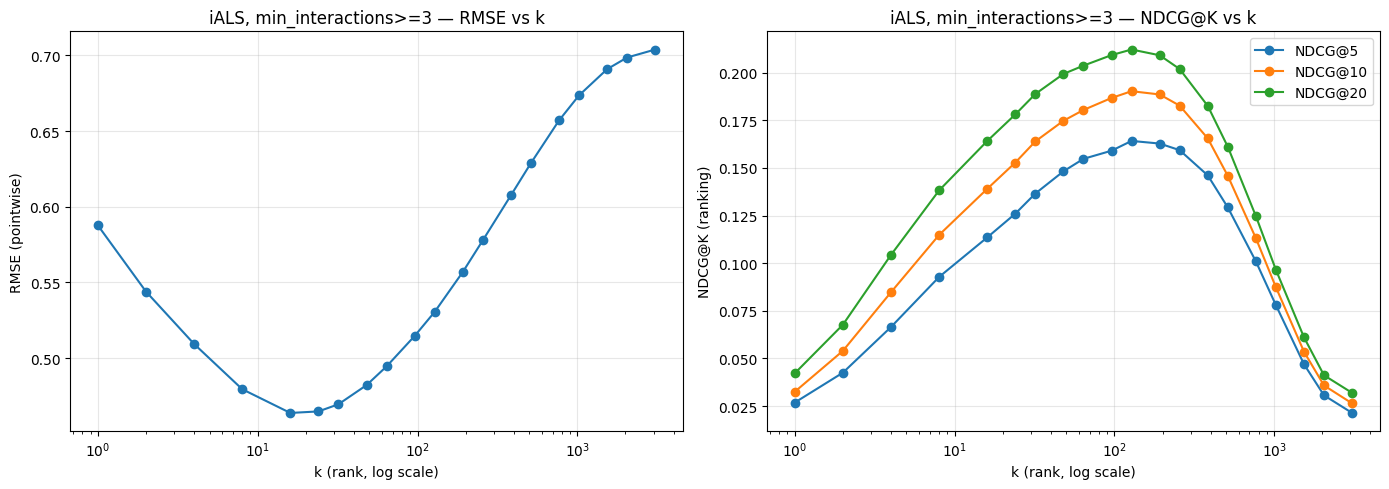

In [19]:
sweep_csv_tau3 = BASE_DIR / "data" / "sweep_results_iterations50.csv"
df_tau3 = run_sweep(sweep_csv_tau3, iterations=50)
THRESHOLD_INFO[3] = dict(n_users=n_users_train, n_items=n_items_train, csv=sweep_csv_tau3)

peak = df_tau3.loc[df_tau3["ndcg@20"].idxmax()]
final = df_tau3[df_tau3["k"] == 3072].iloc[0]
print(f"peak ndcg@20={peak['ndcg@20']:.4f} at k={int(peak['k'])}; at k=3072: {final['ndcg@20']:.4f} "
      f"({final['ndcg@20']/peak['ndcg@20']*100:.1f}% of peak)")

plot_threshold(df_tau3, 3, BASE_DIR / "data" / "double_descent_ials_tau3_only.png")

Single, well-defined peak, then a monotonic decline all the way to `k=3072` — no second rise anywhere in
the tested range. On this (largest, sparsest) population, there is no evidence of double descent.

For reference, here is the same curve compared against an earlier, under-trained run at `iterations=15`
(kept only because it is a useful illustration of the training-time-overfitting effect described in
Section 4.2: the two curves are close for small/medium k and diverge sharply for large k).

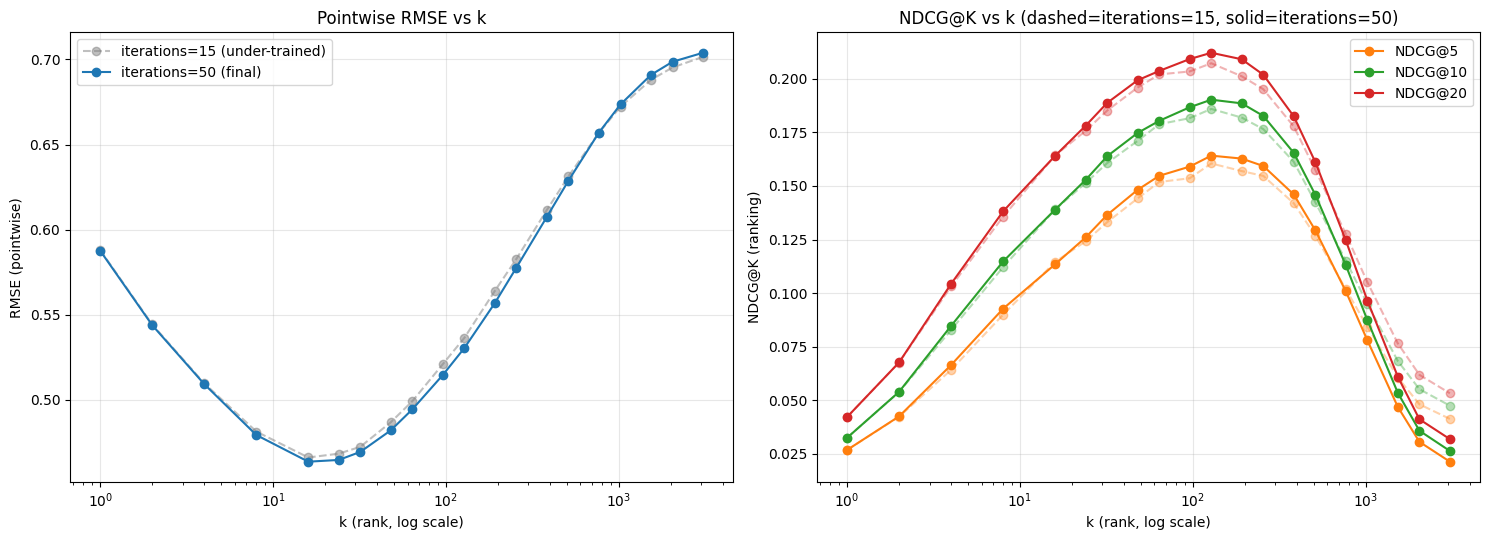

In [21]:
df15 = pd.read_csv(BASE_DIR / "data" / "sweep_results_partial.csv").sort_values("k")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
ax = axes[0]
ax.plot(df15["k"], df15["rmse"], marker="o", linestyle="--", alpha=0.5, color="gray", label="iterations=15 (under-trained)")
ax.plot(df_tau3["k"], df_tau3["rmse"], marker="o", color="C0", label="iterations=50 (final)")
ax.set_xscale("log"); ax.set_xlabel("k (rank, log scale)"); ax.set_ylabel("RMSE (pointwise)")
ax.set_title("Pointwise RMSE vs k"); ax.grid(True, alpha=0.3); ax.legend()

ax = axes[1]
colors = ["C1", "C2", "C3"]
for K, c in zip(METRIC_K_LIST, colors):
    ax.plot(df15["k"], df15[f"ndcg@{K}"], marker="o", linestyle="--", alpha=0.35, color=c)
    ax.plot(df_tau3["k"], df_tau3[f"ndcg@{K}"], marker="o", color=c, label=f"NDCG@{K}")
ax.set_xscale("log"); ax.set_xlabel("k (rank, log scale)"); ax.set_ylabel("NDCG@K (ranking)")
ax.set_title("NDCG@K vs k (dashed=iterations=15, solid=iterations=50)")
ax.grid(True, alpha=0.3); ax.legend()

plt.tight_layout()
plt.savefig(BASE_DIR / "data" / "double_descent_ials_iterations50.png", dpi=150)
plt.show()

### 5.2 Threshold τ=5

min_interactions=5: train users=7802, train items=4236, test users=7765, cold-start test rows dropped=37
peak ndcg@20=0.1820 at k=128; at k=3072: 0.0273 (15.0% of peak)


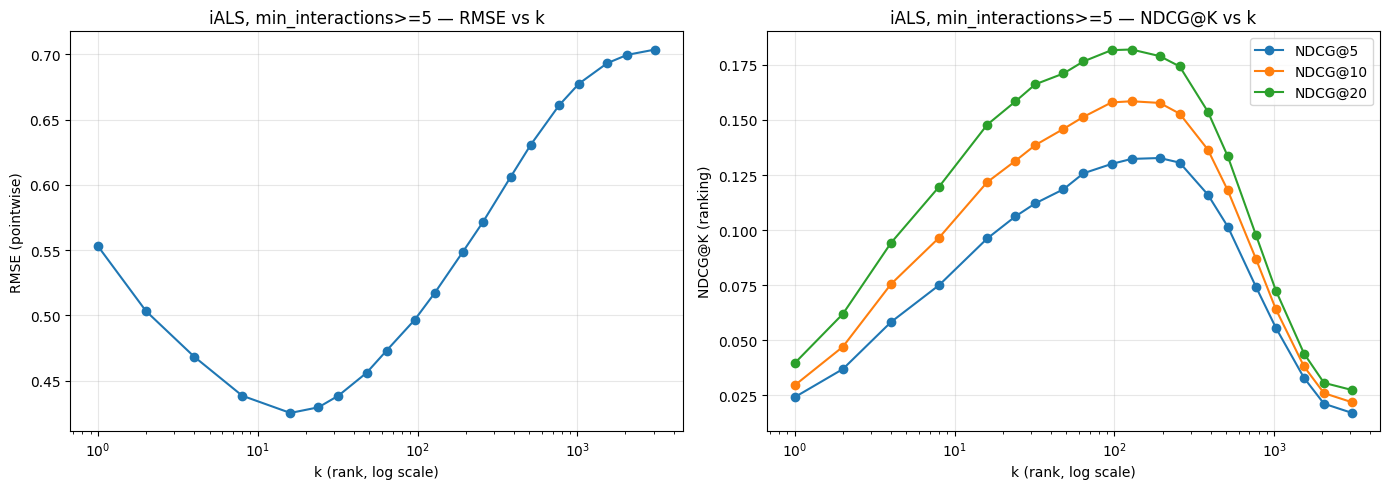

In [23]:
DATA_SPLITS_DIR_5 = BASE_DIR / "data" / "splits_min5"
_data = prepare_threshold_data(5, DATA_SPLITS_DIR_5)
train_csr = _data["train_csr"]; test_user_idx = _data["test_user_idx"]; test_item_idx = _data["test_item_idx"]
neg_items_per_user = _data["neg_items_per_user"]; n_users_train = _data["n_users_train"]; n_items_train = _data["n_items_train"]

sweep_csv_tau5 = BASE_DIR / "data" / "sweep_results_iterations50_min5.csv"
df_tau5 = run_sweep(sweep_csv_tau5, iterations=50)
THRESHOLD_INFO[5] = dict(n_users=n_users_train, n_items=n_items_train, csv=sweep_csv_tau5)

peak = df_tau5.loc[df_tau5["ndcg@20"].idxmax()]
final = df_tau5[df_tau5["k"] == 3072].iloc[0]
print(f"peak ndcg@20={peak['ndcg@20']:.4f} at k={int(peak['k'])}; at k=3072: {final['ndcg@20']:.4f} "
      f"({final['ndcg@20']/peak['ndcg@20']*100:.1f}% of peak)")

plot_threshold(df_tau5, 5, BASE_DIR / "data" / "double_descent_ials_min5.png")

Same qualitative shape as τ=3: a single peak, then an uninterrupted decline. Still no recovery.

### 5.3 Threshold τ=10

min_interactions=10: train users=3665, train items=4077, test users=3641, cold-start test rows dropped=24
peak ndcg@20=0.1418 at k=96; trough=0.0277 at k=2048; at k=3072: 0.0373 (26.3% of peak, +34.7% vs trough)


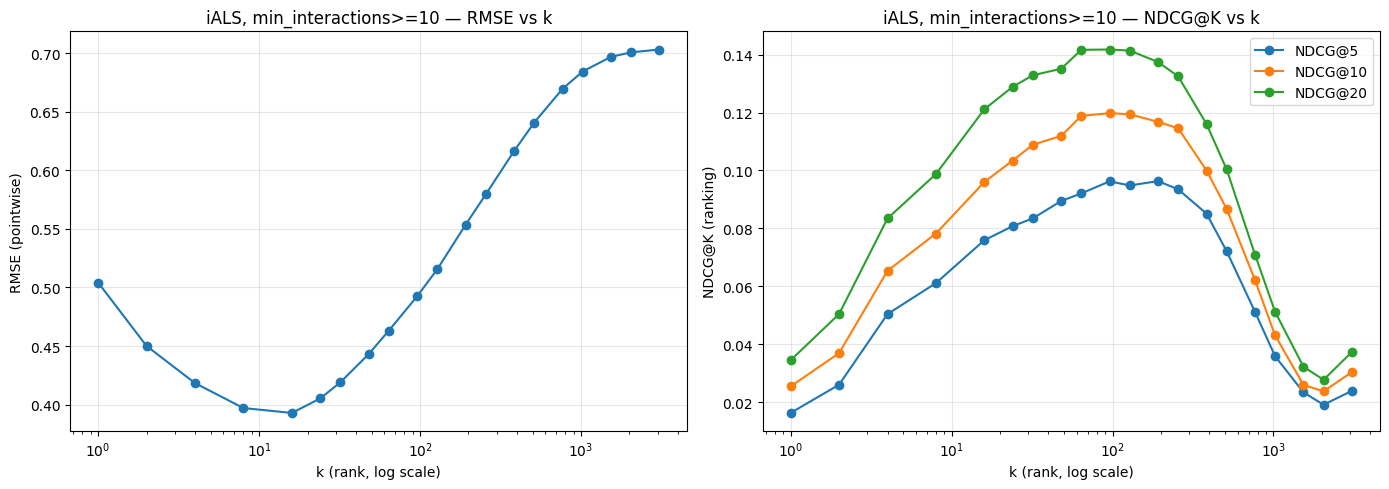

In [26]:
DATA_SPLITS_DIR_10 = BASE_DIR / "data" / "splits_min10"
_data = prepare_threshold_data(10, DATA_SPLITS_DIR_10)
train_csr = _data["train_csr"]; test_user_idx = _data["test_user_idx"]; test_item_idx = _data["test_item_idx"]
neg_items_per_user = _data["neg_items_per_user"]; n_users_train = _data["n_users_train"]; n_items_train = _data["n_items_train"]

sweep_csv_tau10 = BASE_DIR / "data" / "sweep_results_iterations50_min10.csv"
df_tau10 = run_sweep(sweep_csv_tau10, iterations=50)
THRESHOLD_INFO[10] = dict(n_users=n_users_train, n_items=n_items_train, csv=sweep_csv_tau10)

peak = df_tau10.loc[df_tau10["ndcg@20"].idxmax()]
final = df_tau10[df_tau10["k"] == 3072].iloc[0]
trough = df_tau10[df_tau10["k"] > peak["k"]].loc[df_tau10[df_tau10["k"] > peak["k"]]["ndcg@20"].idxmin()]
print(f"peak ndcg@20={peak['ndcg@20']:.4f} at k={int(peak['k'])}; "
      f"trough={trough['ndcg@20']:.4f} at k={int(trough['k'])}; "
      f"at k=3072: {final['ndcg@20']:.4f} ({final['ndcg@20']/peak['ndcg@20']*100:.1f}% of peak, "
      f"{(final['ndcg@20']/trough['ndcg@20'] - 1)*100:+.1f}% vs trough)")

plot_threshold(df_tau10, 10, BASE_DIR / "data" / "double_descent_ials_min10.png")

Here the last grid point shows a genuine (if weak) uptick over the trough — real, but only one point at
the very edge of the tested range, so we cannot tell if the curve keeps rising beyond k=3072.

### 5.4 Threshold τ=20

min_interactions=20: train users=1313, train items=3782, test users=1301, cold-start test rows dropped=12
peak ndcg@20=0.1058 at k=128; trough=0.0418 at k=768; at k=3072: 0.0788 (74.5% of peak)


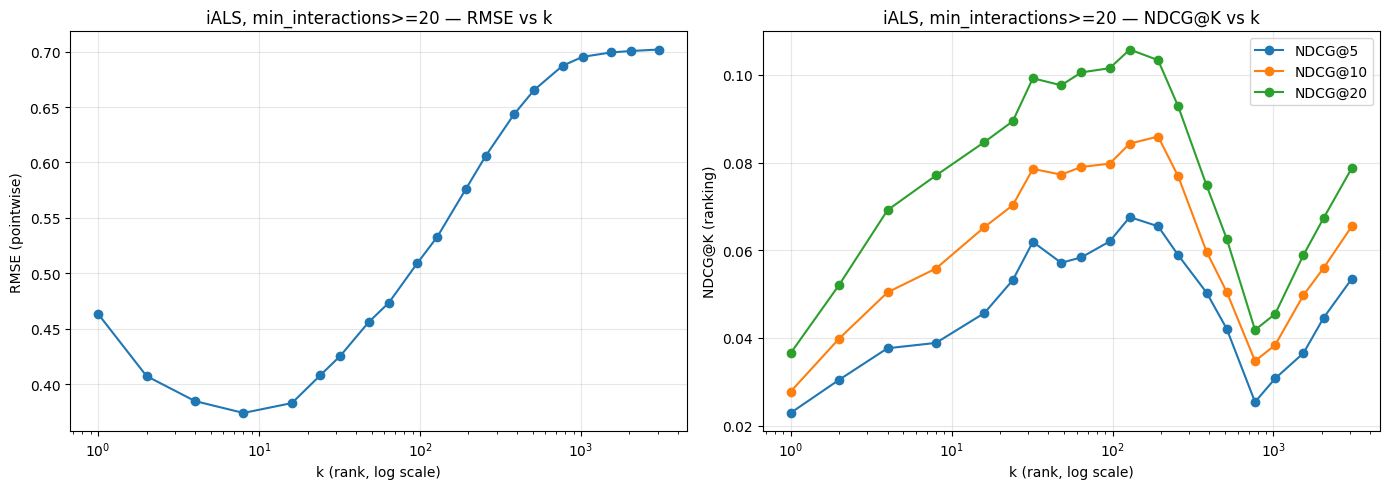

In [29]:
DATA_SPLITS_DIR_20 = BASE_DIR / "data" / "splits_min20"
_data = prepare_threshold_data(20, DATA_SPLITS_DIR_20)
train_csr = _data["train_csr"]; test_user_idx = _data["test_user_idx"]; test_item_idx = _data["test_item_idx"]
neg_items_per_user = _data["neg_items_per_user"]; n_users_train = _data["n_users_train"]; n_items_train = _data["n_items_train"]

sweep_csv_tau20 = BASE_DIR / "data" / "sweep_results_iterations50_min20.csv"
df_tau20 = run_sweep(sweep_csv_tau20, iterations=50)
THRESHOLD_INFO[20] = dict(n_users=n_users_train, n_items=n_items_train, csv=sweep_csv_tau20)

peak = df_tau20.loc[df_tau20["ndcg@20"].idxmax()]
final = df_tau20[df_tau20["k"] == 3072].iloc[0]
trough = df_tau20[df_tau20["k"] > peak["k"]].loc[df_tau20[df_tau20["k"] > peak["k"]]["ndcg@20"].idxmin()]
print(f"peak ndcg@20={peak['ndcg@20']:.4f} at k={int(peak['k'])}; "
      f"trough={trough['ndcg@20']:.4f} at k={int(trough['k'])}; "
      f"at k=3072: {final['ndcg@20']:.4f} ({final['ndcg@20']/peak['ndcg@20']*100:.1f}% of peak)")

plot_threshold(df_tau20, 20, BASE_DIR / "data" / "double_descent_ials_min20.png")

Unambiguous recovery: NDCG@20 rises monotonically over four consecutive grid points after the trough —
much stronger evidence of genuine double-descent behaviour than the single-point uptick at τ=10.

### 5.5 Threshold τ=25 (smallest, densest population; matched to NMF's setup)

τ=25 was chosen to match the NMF team's most restrictive threshold, so the population sizes can be
checked against each other before trusting any cross-model reading later (in the report's conclusion —
this notebook only checks that the *populations* line up, it does not compare the two models' curves).

In [32]:
DATA_SPLITS_DIR_25 = BASE_DIR / "data" / "splits_min25"
_data = prepare_threshold_data(25, DATA_SPLITS_DIR_25)
train_csr = _data["train_csr"]; test_user_idx = _data["test_user_idx"]; test_item_idx = _data["test_item_idx"]
neg_items_per_user = _data["neg_items_per_user"]; n_users_train = _data["n_users_train"]; n_items_train = _data["n_items_train"]

# Sanity check only: NMF's notebook (same threshold, same split logic/seed) reports 916 train users,
# 3667 train items, 899 test users. If the numbers below don't match, the populations have diverged
# and any later cross-model reading (done in the conclusion) would not be comparing like with like.
print(f"iALS  - train users: {n_users_train} | train items: {n_items_train} | test users: {len(np.unique(test_user_idx))}")
print("NMF   - train users: 916 | train items: 3667 | test users: 899  (as reported in their notebook)")

min_interactions=25: train users=916, train items=3667, test users=899, cold-start test rows dropped=17
iALS  - train users: 916 | train items: 3667 | test users: 899
NMF   - train users: 916 | train items: 3667 | test users: 899  (as reported in their notebook)


peak ndcg@20=0.0926 at k=24; at k=3072: 0.0810 (87.5% of peak)
RMSE at k=1: 0.4492; RMSE at k=3072: 0.7016


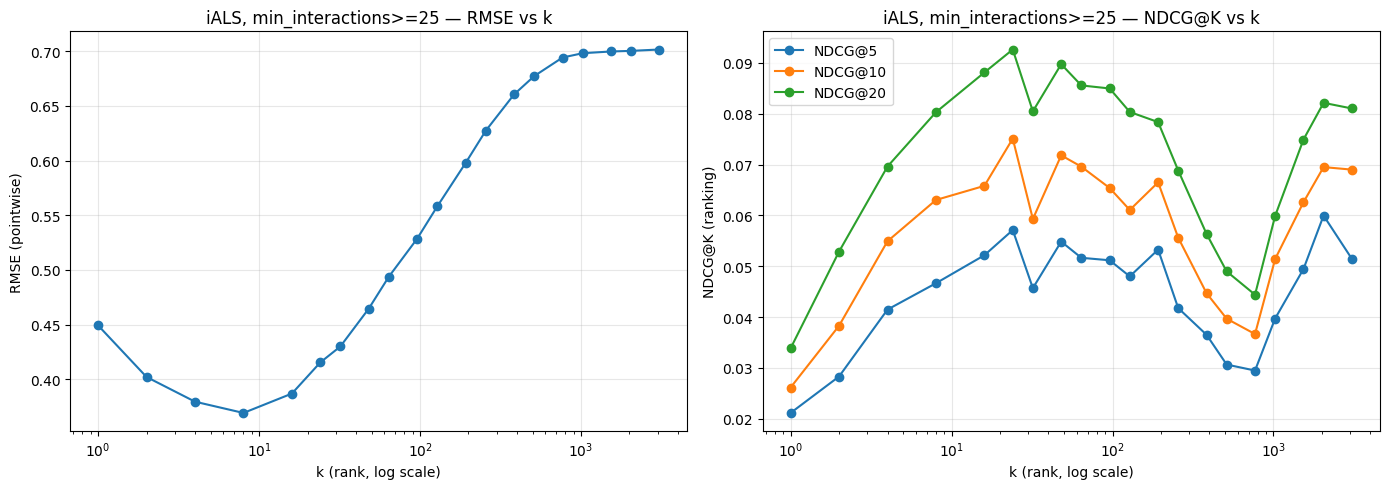

In [33]:
sweep_csv_tau25 = BASE_DIR / "data" / "sweep_results_iterations50_min25.csv"
df_tau25 = run_sweep(sweep_csv_tau25, iterations=50)
THRESHOLD_INFO[25] = dict(n_users=n_users_train, n_items=n_items_train, csv=sweep_csv_tau25)

peak = df_tau25.loc[df_tau25["ndcg@20"].idxmax()]
final = df_tau25[df_tau25["k"] == 3072].iloc[0]
print(f"peak ndcg@20={peak['ndcg@20']:.4f} at k={int(peak['k'])}; at k=3072: {final['ndcg@20']:.4f} "
      f"({final['ndcg@20']/peak['ndcg@20']*100:.1f}% of peak)")
print(f"RMSE at k=1: {df_tau25.iloc[0]['rmse']:.4f}; RMSE at k=3072: {final['rmse']:.4f}")

plot_threshold(df_tau25, 25, BASE_DIR / "data" / "double_descent_ials_min25.png")

The strongest and most complete recovery of the five thresholds. Notably, it only shows up in the
ranking metric — RMSE rises essentially monotonically across the same range, with no second descent.

## 6. A gradient across population size

Having swept five thresholds with the same methodology, we can look at more than just "double descent
present or absent": for each threshold, what fraction of its own peak NDCG@20 is retained at `k=3072`?
Computed directly from the five results files (not typed in by hand).

In [36]:
gradient_rows = []
for tau, info in sorted(THRESHOLD_INFO.items()):
    df = pd.read_csv(info["csv"])
    peak_row = df.loc[df["ndcg@20"].idxmax()]
    final_val = df.loc[df["k"] == 3072, "ndcg@20"].iloc[0]
    gradient_rows.append(dict(
        tau=tau, train_users=info["n_users"], train_items=info["n_items"],
        peak_ndcg20=peak_row["ndcg@20"], peak_k=int(peak_row["k"]),
        final_ndcg20=final_val, fraction_of_peak=final_val / peak_row["ndcg@20"] * 100,
    ))
gradient_df = pd.DataFrame(gradient_rows)
gradient_df

,tau,train_users,train_items,peak_ndcg20,peak_k,final_ndcg20,fraction_of_peak
0,3,11878,4280,0.212107,128,0.031935,15.055921
1,5,7802,4236,0.182022,128,0.027297,14.996452
2,10,3665,4077,0.141775,96,0.037328,26.328811
3,20,1313,3782,0.105780,128,0.078781,74.476003
4,25,916,3667,0.092625,24,0.081025,87.476289


The fraction retained is essentially flat between τ=3 and τ=5, then increases steadily from τ=10 through
τ=25 as the population shrinks (and gets denser — see the density check below).

In [38]:
for tau, info in sorted(THRESHOLD_INFO.items()):
    train = pd.read_csv([p for p in [BASE_DIR/"data"/"splits", BASE_DIR/"data"/f"splits_min{tau}"]
                         if (p/"train.csv").exists()][0] / "train.csv")
    density = len(train) / (info["n_users"] * info["n_items"])
    print(f"tau={tau:2d}: density = {density*100:.3f}% of the user-item matrix")

tau= 3: density = 0.216% of the user-item matrix
tau= 5: density = 0.332% of the user-item matrix
tau=10: density = 0.735% of the user-item matrix
tau=20: density = 2.211% of the user-item matrix
tau=25: density = 3.269% of the user-item matrix


## 7. Caveat: is this a population effect, or just how far we looked?

The gradient table above uses the same `k_max=3072` for every threshold, but `n+m` shrinks a lot as τ
grows — so `k_max` reaches a very different *relative* depth of overparameterization at each threshold.
Part of the apparent gradient could simply be that the smaller populations were probed further into the
overparameterized regime in relative terms, not that they behave differently at a given relative depth.
To check this, each curve is truncated to the largest `k` in its own grid that does not exceed τ=3's
relative depth (`k/(n+m) <= depth_tau3`), and we compare the recovered fraction at that matched depth.

In [40]:
depth_tau3 = 3072 / (THRESHOLD_INFO[3]["n_users"] + THRESHOLD_INFO[3]["n_items"])
print(f"Reference relative depth (tau=3, k=3072): {depth_tau3:.3f}x (n+m)")

depth_rows = []
for tau, info in sorted(THRESHOLD_INFO.items()):
    df = pd.read_csv(info["csv"]).sort_values("k")
    n_plus_m = info["n_users"] + info["n_items"]
    own_depth = 3072 / n_plus_m
    target_k = depth_tau3 * n_plus_m
    matched_k = df.loc[df["k"] <= target_k, "k"].max()
    val_at_matched = df.loc[df["k"] == matched_k, "ndcg@20"].iloc[0]
    peak = df["ndcg@20"].max()
    depth_rows.append(dict(tau=tau, own_depth_at_k3072=own_depth, matched_k=int(matched_k),
                            ndcg20_at_matched_k=val_at_matched, peak=peak,
                            fraction_of_peak=val_at_matched / peak * 100))
depth_df = pd.DataFrame(depth_rows)
depth_df

Reference relative depth (tau=3, k=3072): 0.190x (n+m)


,tau,own_depth_at_k3072,matched_k,ndcg20_at_matched_k,peak,fraction_of_peak
0,3,0.190123,3072,0.031935,0.212107,15.055921
1,5,0.255192,2048,0.030565,0.182022,16.791980
2,10,0.396797,1024,0.051133,0.141775,36.066334
3,20,0.602944,768,0.041813,0.105780,39.528098
4,25,0.670303,768,0.044401,0.092625,47.936720


Two things follow. First, the scale confound is real: it inflates the raw gradient reported in Section 6
— roughly half of the apparent 15%→88% spread is attributable to smaller populations simply being probed
further into the overparameterized regime with the same `k_max`. Second, the confound does not fully
explain it: at matched relative depth, τ=10/20/25 still retain markedly more of their peak than τ=3/5, a
gap that is not explained by how far we happened to look. We do not claim to have cleanly separated a
"population/density" effect from a "capacity depth" effect — doing that rigorously would mean extending
`K_GRID` for τ=3 and τ=5 out to the same relative depth reached at τ=25 (roughly k≈10,800 and k≈8,000
respectively), which was not run given the CPU cost already observed at k=3072 for the current grid.

## 8. Discussion

With the caveat above in mind, the main finding still stands: double descent in this model is not simply
absent. At matched relative depth, the smaller/denser populations (τ≥10) retain roughly twice the
fraction of their peak that the two larger populations do, so some genuine population-dependent effect
survives the scale correction, even if we cannot yet pin its size down exactly.

A speculative explanation: this model fits the *entire* user-item matrix with an explicit L2 penalty at
every k, so there is no finite, fixed set of cells it can exactly interpolate the way a model trained on a
small sampled support could. That would make the double-descent mechanism weaker, and more dependent on
how sparse or dense the population is. This is a hypothesis consistent with what we observed here, not
something verified directly — a genuine comparison against the other two models in this project is left
to the report's concluding section, where all three models are read on the same terms.

## 9. Limitations

A few things were not fully controlled for and should be stated plainly:

- The `iterations=50` choice was validated (via the Section 4 convergence check) only at τ=3, at k=128
  and k=3072. We did not re-verify that 50 iterations is appropriate at τ=10/20/25, where k=3072 is an
  even more extreme multiple of the population size.
- Every run here uses a single fixed seed for both the data split and the model's initialization. The
  weaker signals — in particular the single-point uptick at τ=10 — have not been checked for robustness
  across multiple seeds and could partly reflect the variance of one particular run.
- The five thresholds were not fixed in advance as a pre-registered design: τ=10 and τ=20 were added
  after τ=25 showed an unexpected recovery, specifically to test whether it was a gradient or an
  isolated case. The resulting pattern should be read as hypothesis-generating evidence, not as a
  confirmatory test of a claim fixed before seeing the data.